# 02 · Máquinas y grupos de máquinas

Este notebook construye la tabla que asigna cada máquina a su grupo (familia) y selecciona
las familias de máquinas productivas con las que se trabaja en el resto del proyecto.

- **Entrada:** `SmNodo.csv`, `CPRMachine.csv`, `CPRMachineGroup.csv`, `CPRMachineGroupElement.csv` (en `data/raw/`) y `data/processed/df_imputations_limpieza.parquet`
- **Salida:** `data/processed/maquina_grupo.parquet` y `results/tables/embudo_02.json`

In [65]:
import sys
from pathlib import Path

# Raíz del repositorio (localizar la carpeta que contiene src/) para poder importar src
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ)) # asignar la ruta del proyecto a sys.path

import matplotlib.pyplot as plt
import pandas as pd

from src.columnas import (COLUMNAS_GRUPOS, COLUMNAS_MAQUINA_GRUPO, COLUMNAS_MAQUINAS,
                          COLUMNAS_NODOS, leer_csv)
from src.embudo import guardar_embudo, tabla_embudo
from src.rutas import FIGURES, PROCESSED

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

embudo = {}  # número de máquinas que quedan tras cada paso

## 1. Nodos del MES

La tabla que contiene las máquinas pertenece al sistema MES y muestra todos los nodos desde los que es posible realizar imputaciones.    

Se entiende como nodo cualquier entidad que permita capturar datos y que represente un
lugar de trabajo de la planta: un nodo puede ser una máquina, pero también un centro de trabajo, un despacho o cualquier punto desde el que se quiera capturar el estado de la producción.     

In [66]:
df_nodos = leer_csv("SmNodo.csv", COLUMNAS_NODOS)

print(df_nodos.shape)
df_nodos[["smNodoId", "smNodoNme"]].head()

(119, 24)


,smNodoId,smNodoNme
0,MN,Montatge Pneumàtic i hidràulic
1,TL05,Taladre LÍDER E-25
2,SL01,Soldadura elèctrode KEMPPY Minarc 150
3,FO04,Forn TTC
4,XO01,Xorrejar NORBLAST VMS-1-0-90


Hay 119 nodos, de los cuales solo interesan los que son máquinas.

## 2. Máquinas y grupos del ERP

Las máquinas se trabajan desde el ERP, donde se presentan con sus grupos. Hay tres tablas:

- `df_machines`: todas las máquinas del ERP (deberían coincidir con los nodos del MES, tabla SmNodo).
- `df_machines_group`: todos los grupos de máquinas del ERP.
- `df_machines_relaciones`: a qué grupo pertenece cada máquina.

Solo se trabaja con las máquinas de la planta 100 (`CodCompany = 100`).

In [67]:
df_machines = leer_csv("CPRMachine.csv", COLUMNAS_MAQUINAS)
df_machines_group = leer_csv("CPRMachineGroup.csv", COLUMNAS_GRUPOS)
df_machines_relaciones = leer_csv("CPRMachineGroupElement.csv", COLUMNAS_MAQUINA_GRUPO)

df_machines = df_machines[df_machines["CodCompany"] == 100]
df_machines_group = df_machines_group[df_machines_group["CodCompany"] == 100]
df_machines_relaciones = df_machines_relaciones[df_machines_relaciones["CodCompany"] == 100]

print(f"Máquinas: {len(df_machines)}")
print(f"Grupos de máquinas: {len(df_machines_group)}")
print(f"Relaciones máquina–grupo: {len(df_machines_relaciones)}")

embudo["Máquinas iniciales"] = len(df_machines)
familias_iniciales = len(df_machines_group)

Máquinas: 120
Grupos de máquinas: 57
Relaciones máquina–grupo: 115


## 3. Máquinas del ERP que no están en el MES

Se comprueba que las máquinas de `df_machines` (ERP) coincidan con las de `df_nodos` (MES).

In [68]:
compara = df_machines.merge(df_nodos, left_on="CodMachine", right_on="smNodoId",
                            how="outer", indicator=True).query("_merge != 'both'")

lista_solo_machines = compara.loc[compara["_merge"] == "left_only", "CodMachine"].tolist()  # en ERP, no en MES
lista_solo_nodos = compara.loc[compara["_merge"] == "right_only", "smNodoId"].tolist()      # en MES, no en ERP

print(f"Máquinas en ERP pero no en MES: {lista_solo_machines}")
print(f"Máquinas en MES pero no en ERP: {lista_solo_nodos}")

Máquinas en ERP pero no en MES: ['TU06']
Máquinas en MES pero no en ERP: []


La máquina que no están en el MES se elimina de `df_machines`: si no están en el MES no pueden recibir imputaciones. Es una máquina dada de baja. 
          
El proyecto solo trabaja con máquinas que permiten imputaciones.

In [69]:
df_machines = df_machines[~df_machines["CodMachine"].isin(lista_solo_machines)]
embudo["Máquinas activas en MES"] = len(df_machines)
print(f"Máquinas: {len(df_machines)}")

Máquinas: 119


## 4. Tabla máquina–grupo

Se crea una tabla que indica a qué grupo pertenece cada máquina.

In [70]:
rel = df_machines_relaciones.merge(df_machines_group, on="IDMachineGroup", how="left")
maquina_grupo = df_machines.merge(rel, on="IDMachine", how="left")

# Columnas útiles, con nombres más legibles
maquina_grupo = maquina_grupo[["IDMachine", "CodMachine", "Description_x",
                               "IDMachineGroup", "CodMachineGroup", "Description_y"]]
maquina_grupo = maquina_grupo.rename(columns={"IDMachine": "IDMaquina", "CodMachine": "CodigoMaquina",
                                              "Description_x": "NombreMaquina", "IDMachineGroup": "IDGrupo",
                                              "CodMachineGroup": "CodigoGrupo", "Description_y": "NombreGrupo"})

print(f"Máquinas: {len(df_machines)} | filas en la tabla máquina–grupo: {len(maquina_grupo)}")

Máquinas: 119 | filas en la tabla máquina–grupo: 124


Hay 119 máquinas, pero la tabla tiene 124 filas: algunas máquinas aparecen en más de un grupo.   

Se localizan para revisarlas.

In [71]:
conteo = maquina_grupo["IDMaquina"].value_counts()
ids_multi = conteo[conteo > 1].index
print(f"Máquinas en más de un grupo: {len(ids_multi)}")

maquina_grupo[maquina_grupo["IDMaquina"].isin(ids_multi)][
    ["CodigoMaquina", "NombreMaquina", "CodigoGrupo", "NombreGrupo"]
].sort_values("CodigoMaquina")

Máquinas en más de un grupo: 5


,CodigoMaquina,NombreMaquina,CodigoGrupo,NombreGrupo
84,AK05,ACABATS ALU 01,MA-ALU,Màquines Auxiliars Aluminis
85,AK05,ACABATS ALU 01,AKS-ALU,Llocs de treball Secció Acabats ALUMINI
14,FT02,LAGUN FTV4,FU-ALU,Freses Universals Aluminis
15,FT02,LAGUN FTV4,FU,Freses Universals
98,FU03,FU MRF FU 145,ENG,Engineering
99,FU03,FU MRF FU 145,FU,Freses Universals
29,FU05,FU DECKEL 2027-2181,ENG,Engineering
30,FU05,FU DECKEL 2027-2181,FU,Freses Universals
92,FU07,FU MRF FU 145,FU,Freses Universals
93,FU07,FU MRF FU 145,ENG,Engineering


Una máquina no puede estar en dos grupos a la vez. Con el equipo de producción se decide descartar estas asignaciones:

- AK05 ACABATS ALU 01 — AKS-ALU Llocs de treball Secció Acabats ALUMINI
- FT02 LAGUN FTV4 — FU Freses Universals
- FU03 FU MRF FU 145 — ENG Engineering
- FU05 FU DECKEL 2027-2181 — ENG Engineering
- FU07 FU MRF FU 145 — ENG Engineering

In [72]:
a_eliminar = [
    ("AK05", "AKS-ALU"),
    ("FT02", "FU"),
    ("FU03", "ENG"),
    ("FU05", "ENG"),
    ("FU07", "ENG"),
]

# Máscara de las filas (máquina, grupo) que se descartan
mask_elim = maquina_grupo.set_index(["CodigoMaquina", "CodigoGrupo"]).index.isin(a_eliminar)
print(f"Filas a eliminar (debe ser 5): {mask_elim.sum()}")

maquina_grupo = maquina_grupo[~mask_elim]
print(f"Filas en la tabla máquina–grupo: {len(maquina_grupo)}")

Filas a eliminar (debe ser 5): 5
Filas en la tabla máquina–grupo: 119


> Cada máquina queda ahora en un único grupo.

## 5. Criterio de alcance: máquinas de mecanizado productivas

Para este estudio se ha decidido trabajar únicamente con las fases cuya ejecución recae sobre una máquina productiva, dejando fuera las que corresponden a actividades como diseño, programación, montaje, control de calidad o trazabilidad, ya que tienen un gran factor humano.

El motivo es coherente con la propia variable que se quiere estudiar: la desviación entre el tiempo real y el teórico solo tiene sentido como apoyo estratégico cuando hay una máquina concreta con alternativas equivalentes entre las que elegir. 
           
En las tareas en las que el factor principal de la desviación no lo marca la máquina, sino la variabilidad propia del factor humano, este trabajo no cobra sentido.        
          
Por la misma razón se han de descartar los nodos genéricos o auxiliares (como "máquina genérica" o "máquina auxiliar"): aunque sí repercuten sobre un recurso productivo, no identifican qué máquina se usó realmente, así que no permiten analizar la idoneidad a nivel de máquina, que es justo lo que persigue este trabajo. Estos puestos de trabajo se utilizan como "comodín" sin especificar una máquina concreta. 

En definitiva, este recorte dejara el análisis centrado en las operaciones donde la asignación de máquina es una decisión real con incertidumbre, que es donde el estudio aporta valor. 



## 6. Máquinas sin grupo

Primero se revisan las máquinas que no pertenecen a ningún grupo, para eliminar las que no cumplen la definición
y asignar un grupo a las que deben mantenerse.

In [73]:
sin_grupo = maquina_grupo[maquina_grupo["IDGrupo"].isna()]
print(f"Máquinas sin grupo: {len(sin_grupo)}")
sin_grupo[["CodigoMaquina", "NombreMaquina"]].sort_values("CodigoMaquina")

Máquinas sin grupo: 10


,CodigoMaquina,NombreMaquina
79,AK06,ACABATS COURES 05
83,CM01,CHO MX60HB OKUMA
71,CM04,CV MICROCUT Ch1300
54,CM15,C5 IBARMIA ZVH45
90,PR07,CAM CU 04
9,RE,Resolució punts pendents
8,REP,Reparació de peces
96,RO02,Roscamat Elèctric
112,SG02,Autogena GALASOL 2
101,SO,"Peces Client: Soldadura (assajos, tests...)"


Los nodos Roscamat Elèctric (RO02), CAM CU 04 (PR07), ACABATS COURES 05 (AK06), Resolució punts pendents (RE),
Reparació de peces (REP) y Peces Client: Soldadura (SO) no son máquinas productivas y se descartan.

En el mismo paso se descartan dos máquinas que sí tienen grupo: PH02, porque solo se usa con una misma OF durante años (es un caso muy particular de producción), y MC02, porque su registro de imputaciones tiene una cantidad de ruido intratable.

In [74]:
nodos_no_productivos = ["RO02", "PR07", "AK06", "RE", "REP", "SO",  # nodos sin grupo
                        "PH02", "MC02"]                              # máquinas con grupo

mask_quitar = maquina_grupo["CodigoMaquina"].isin(nodos_no_productivos)
print(f"Filas antes: {len(maquina_grupo)} | se eliminan (esperado 8): {mask_quitar.sum()}")
maquina_grupo = maquina_grupo[~mask_quitar]
print(f"Filas restantes: {len(maquina_grupo)}")

sin_grupo = sin_grupo[~sin_grupo["CodigoMaquina"].isin(nodos_no_productivos)]
print(f"Máquinas sin grupo que quedan: {len(sin_grupo)}")
sin_grupo[["CodigoMaquina", "NombreMaquina"]].sort_values("CodigoMaquina")

Filas antes: 119 | se eliminan (esperado 8): 8
Filas restantes: 111
Máquinas sin grupo que quedan: 4


,CodigoMaquina,NombreMaquina
83,CM01,CHO MX60HB OKUMA
71,CM04,CV MICROCUT Ch1300
54,CM15,C5 IBARMIA ZVH45
112,SG02,Autogena GALASOL 2


Estas cuatro máquinas sí deben pertenecer a un grupo. Con el equipo de producción se acuerda esta asignación:

- C5 IBARMIA ZVH45 → Centre Mecanitzat 5 Eixos petites
- CV MICROCUT Ch1300 → Centres de Mecanitzat Vertical ALUMINIS
- CHO MX60HB OKUMA → Centres de Mecanitzat Horitzontal COURES
- Autogena GALASOL 2 → Màquines Auxiliars Soldadura

In [75]:
def asignar_grupos(df, asignaciones, df_grupos):
    """
    Rellena el grupo de las máquinas huérfanas (grupo = NaN).
        df           : maquina_grupo
        asignaciones : dict {CodigoMaquina: CodigoGrupo}
        df_grupos    : df_machines_group, para recuperar IDGrupo y NombreGrupo a partir del código
    """
    df = df.copy()

    for cod_maquina, cod_grupo in asignaciones.items():
        # grupo destino en la tabla de grupos
        fila_grupo = df_grupos[df_grupos["CodMachineGroup"] == cod_grupo]
        if fila_grupo.empty:
            print(f"Aviso: grupo '{cod_grupo}' no encontrado; {cod_maquina} queda sin asignar")
            continue

        id_grupo = fila_grupo["IDMachineGroup"].iloc[0]
        nombre_grupo = fila_grupo["Description"].iloc[0]

        # máscara de la máquina huérfana
        mask = (df["CodigoMaquina"] == cod_maquina) & (df["IDGrupo"].isna())
        if mask.sum() == 0:
            print(f"Aviso: {cod_maquina} no está huérfana (o no existe); revisar")
            continue

        df.loc[mask, "IDGrupo"] = id_grupo
        df.loc[mask, "CodigoGrupo"] = cod_grupo
        df.loc[mask, "NombreGrupo"] = nombre_grupo
        print(f"{cod_maquina} → {nombre_grupo}")

    return df

In [76]:
asignaciones = {
    # CodigoMaquina: CodigoGrupo
    "CM15": "C5",      # Centre Mecanitzat 5 Eixos petites
    "CM04": "CV-ALU",  # Centres de Mecanitzat Vertical ALUMINIS
    "CM01": "CH",      # Centres de Mecanitzat Horitzontal COURES
    "SG02": "MA-SOL",  # Màquines Auxiliars Soldadura
}

maquina_grupo = asignar_grupos(maquina_grupo, asignaciones, df_machines_group)
print(f"Máquinas sin grupo: {maquina_grupo['IDGrupo'].isna().sum()}")

CM15 → Centre de Mecanitzat 5 Eixos petites
CM04 → Centres de Mecanitzat Vertical ALUMINIS
CM01 → Centres de Mecanitzat Horitzontal COURES
SG02 → Màquines Auxiliars Soldadura
Máquinas sin grupo: 0


> Todas las máquinas ahora ya quedan asignadas a un grupo.

## 7. Grupos no productivos

Con la tabla de máquinas y grupos completa, se estudia la importancia de cada grupo según el número de imputaciones que acumula. 

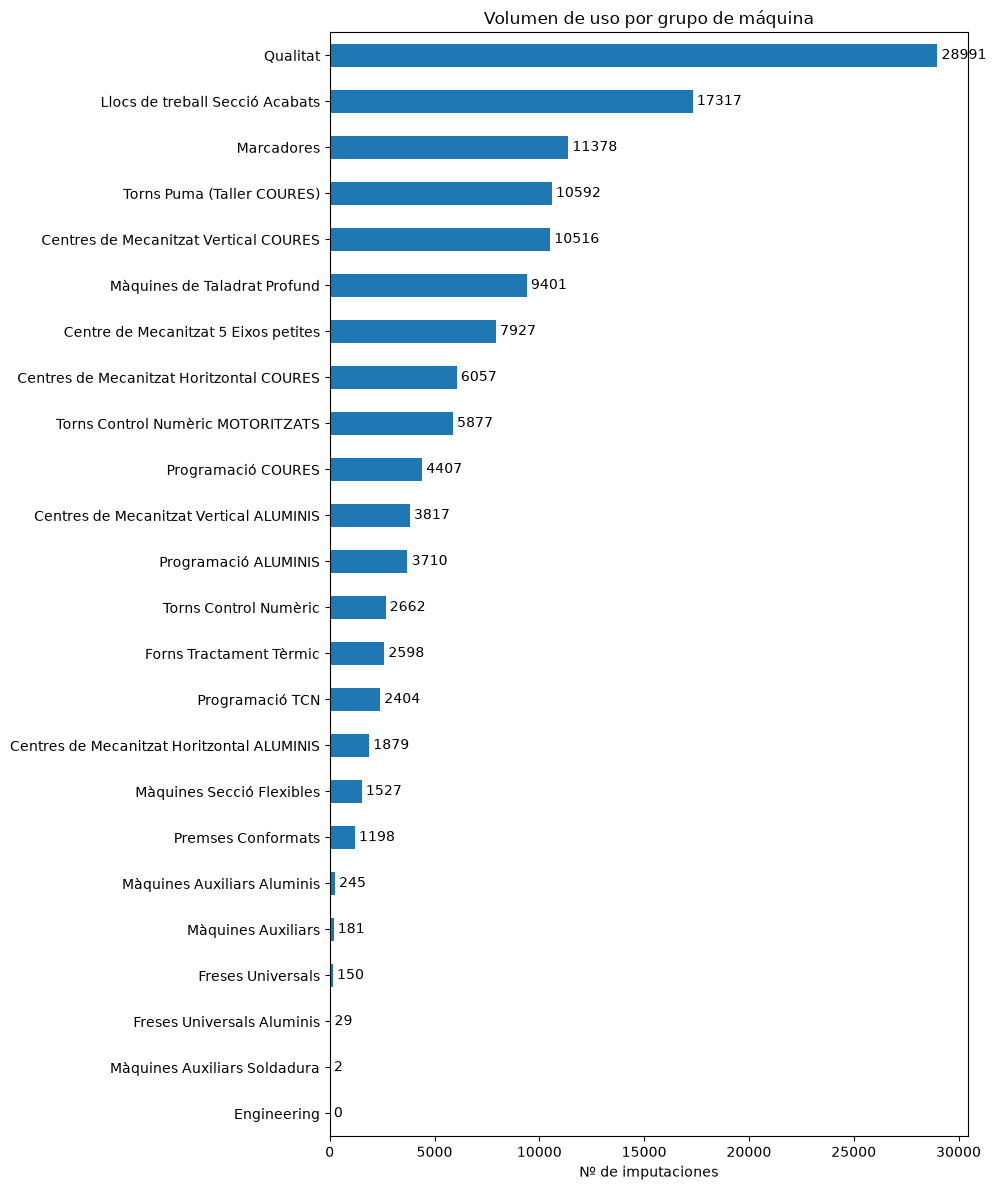

In [77]:
df_imputations_limpieza = pd.read_parquet(PROCESSED / "df_imputations_limpieza.parquet")

# Volumen de uso por máquina
uso = df_imputations_limpieza["smNodoId"].value_counts().rename("num_imputaciones")
tabla_decision = maquina_grupo.merge(uso, left_on="CodigoMaquina", right_index=True, how="left")

uso_grupo = tabla_decision.groupby("NombreGrupo")["num_imputaciones"].sum().astype(int).sort_values()

ax = uso_grupo.plot(kind="barh", figsize=(10, 12))
ax.bar_label(ax.containers[0], padding=3)
ax.set_ylabel("")
plt.xlabel("Nº de imputaciones")
plt.title("Volumen de uso por grupo de máquina")
plt.tight_layout()
plt.savefig(FIGURES / "02_imputaciones_por_grupo.png", dpi=200, bbox_inches="tight")
plt.show()

Este volumen de imputaciones por grupo de máquinas es el mapa bruto de la futura población de estudio. De todos los grupos se prescinde de los que no se consideran productivos, es decir, aquellos cuya productividad no depende de la máquina.
     
De los grupos de máquina disponibles se han excluido del análisis aquellos cuya naturaleza no se corresponde con operaciones de mecanizado productivo, por no ser coherentes con la variable objetivo del estudio. En concreto, se han descartado los grupos de ingeniería ("Engineering"), de programación ("Programació TCN", "Programació
ALUMINIS" y "Programació COURES") y de calidad y acabados ("Qualitat" y "Llocs de treball Secció Acabats").
     
La razón de fondo es común a los tres bloques es el criterio de _Maquina de Mecanizados Productiva_ esmentada anteriormente. En las tareas de ingeniería y de programación (CAM, control numérico) el tiempo empleado depende fundamentalmente del
factor humano y de la complejidad del trabajo a preparar, no de la máquina asignada, por lo que su desviación no informa sobre la idoneidad de ninguna asignación máquina-fase. De forma análoga, las actividades de control de calidad y de acabados constituyen operaciones de verificación y de tratamiento final que no forman parte del
proceso de mecanizado cuya mejora persigue este trabajo.

Junto a estos grupos se descarta también el grupo "Marcadores".

In [78]:
grupos_no_productivos = [
    "Engineering",
    "Qualitat",
    "Llocs de treball Secció Acabats",
    "Programació TCN",
    "Programació ALUMINIS",
    "Programació COURES",
    "Marcadores",
]

mask_fuera = maquina_grupo["NombreGrupo"].isin(grupos_no_productivos)
print(f"Grupos que se eliminan: {sorted(maquina_grupo.loc[mask_fuera, 'NombreGrupo'].unique())}")
print(f"Máquinas que se van con ellos: {mask_fuera.sum()}")

maquina_grupo = maquina_grupo[~mask_fuera]
embudo["Máquinas productivas"] = len(maquina_grupo)
print(f"Máquinas restantes: {len(maquina_grupo)}")

Grupos que se eliminan: ['Engineering', 'Llocs de treball Secció Acabats', 'Marcadores', 'Programació ALUMINIS', 'Programació COURES', 'Programació TCN', 'Qualitat']
Máquinas que se van con ellos: 35
Máquinas restantes: 76


## 8. Grupos con volumen insuficiente

Volumen de imputaciones de los grupos productivos que quedan:

In [79]:
tabla_decision = maquina_grupo.merge(uso, left_on="CodigoMaquina", right_index=True, how="left")
uso_grupo = tabla_decision.groupby("NombreGrupo")["num_imputaciones"].sum().astype(int).sort_values()
uso_grupo.to_frame()

,num_imputaciones
NombreGrupo,
Màquines Auxiliars Soldadura,2
Freses Universals Aluminis,29
Freses Universals,150
Màquines Auxiliars,181
Màquines Auxiliars Aluminis,245
Premses Conformats,1198
Màquines Secció Flexibles,1527
Centres de Mecanitzat Horitzontal ALUMINIS,1879
Forns Tractament Tèrmic,2598


Las familias de cobre (COURES) tienen mucho más volumen que las de aluminio (ALUMINIS): por ejemplo, Centres de
Mecanitzat Vertical COURES suma 10.516 imputaciones frente a 3.817 de Centres de Mecanitzat Vertical ALUMINIS.
Es un dato de contexto sobre el mix de producción de la planta.

Se descartan por volumen insuficiente de imputaciones los grupos Màquines Auxiliars Soldadura, Freses Universals
Aluminis, Màquines Auxiliars y Freses Universals. Son los cuatro de menor volumen (entre 2 y 181 imputaciones);
el siguiente, Màquines Auxiliars Aluminis, suma 245.

In [80]:
grupos_poco_volumen = [
    "Màquines Auxiliars Soldadura",
    "Freses Universals Aluminis",
    "Màquines Auxiliars",
    "Freses Universals",
]

mask_fuera = maquina_grupo["NombreGrupo"].isin(grupos_poco_volumen)
print(f"Máquinas que se eliminan: {mask_fuera.sum()}")
maquina_grupo = maquina_grupo[~mask_fuera]
embudo["Máquinas con suficientes imputaciones"] = len(maquina_grupo)
print(f"Máquinas restantes: {len(maquina_grupo)}")

maquinas_finales = maquina_grupo["CodigoMaquina"].unique()
imput_finales = df_imputations_limpieza[df_imputations_limpieza["smNodoId"].isin(maquinas_finales)]
print(f"\nImputaciones del dataset: {len(df_imputations_limpieza)}")
print(f"Imputaciones en los grupos que quedan: {len(imput_finales)}")

Máquinas que se eliminan: 38
Máquinas restantes: 38

Imputaciones del dataset: 140485
Imputaciones en los grupos que quedan: 64296


## 9. Familias con una sola máquina

Se revisa cuántas máquinas tiene cada grupo.

In [81]:
resumen_familia = maquina_grupo.groupby("NombreGrupo").agg(
    n_maquinas=("CodigoMaquina", "nunique"),
).sort_values("n_maquinas", ascending=False)

print(f"Total de familias: {len(resumen_familia)}")
resumen_familia

Total de familias: 13


,n_maquinas
NombreGrupo,
Màquines Secció Flexibles,5
Premses Conformats,5
Forns Tractament Tèrmic,4
Centres de Mecanitzat Vertical COURES,4
Centre de Mecanitzat 5 Eixos petites,4
Centres de Mecanitzat Horitzontal COURES,3
Centres de Mecanitzat Vertical ALUMINIS,3
Torns Control Numèric MOTORITZATS,3
Torns Puma (Taller COURES),2


Decisiones según el número de máquinas:

- Centres de Mecanitzat Horitzontal ALUMINIS y Màquines Auxiliars Aluminis tienen una sola máquina y se descartan:
  con una única máquina no hay posibilidad de elección dentro de la familia.
- Torns Control Numèric tiene una sola máquina. Se une con Torns Control Numèric MOTORITZATS en una familia que se
  llama Torns Control Numèric.
- Forns Tractament Tèrmic: según producción, aunque en el sistema hay 4 máquinas, en el taller solo se emplea una.
  Se descarta la familia.

In [82]:
# 1. Fusión de los tornos de control numérico
fila_no_motor = maquina_grupo[maquina_grupo["NombreGrupo"] == "Torns Control Numèric"]
if len(fila_no_motor) != 1:
    raise ValueError(f"Se esperaba 1 fila para 'Torns Control Numèric' y hay {len(fila_no_motor)}")

# ID y código reales del grupo no motorizado, antes de tocar nada
id_grupo_real = fila_no_motor["IDGrupo"].iloc[0]
codigo_grupo_real = fila_no_motor["CodigoGrupo"].iloc[0]

mask_motor = maquina_grupo["NombreGrupo"] == "Torns Control Numèric MOTORITZATS"
print(f"Máquinas en Torns Control Numèric: 1 | en MOTORITZATS: {mask_motor.sum()}")

maquina_grupo.loc[mask_motor, "NombreGrupo"] = "Torns Control Numèric"
maquina_grupo.loc[mask_motor, "CodigoGrupo"] = codigo_grupo_real
maquina_grupo.loc[mask_motor, "IDGrupo"] = id_grupo_real

fusion = maquina_grupo[maquina_grupo["NombreGrupo"] == "Torns Control Numèric"]
print(f"Tras la fusión: {len(fusion)} máquinas, {fusion['IDGrupo'].nunique()} ID de grupo "
      f"y {fusion['CodigoGrupo'].nunique()} código de grupo (código {codigo_grupo_real})")

Máquinas en Torns Control Numèric: 1 | en MOTORITZATS: 3
Tras la fusión: 4 máquinas, 1 ID de grupo y 1 código de grupo (código TCN)


In [83]:
# 2. Descarte de las familias de una sola máquina y de Forns Tractament Tèrmic
grupos_a_descartar = [
    "Centres de Mecanitzat Horitzontal ALUMINIS",
    "Màquines Auxiliars Aluminis",
    "Forns Tractament Tèrmic",
]
for g in grupos_a_descartar:
    print(f"{g}: {(maquina_grupo['NombreGrupo'] == g).sum()} máquinas")

maquina_grupo = maquina_grupo[~maquina_grupo["NombreGrupo"].isin(grupos_a_descartar)]
embudo["Máquinas en familias válidas"] = len(maquina_grupo)
print(f"\nMáquinas restantes: {len(maquina_grupo)}")

Centres de Mecanitzat Horitzontal ALUMINIS: 1 máquinas
Màquines Auxiliars Aluminis: 1 máquinas
Forns Tractament Tèrmic: 4 máquinas

Máquinas restantes: 32


In [84]:
resumen_familia = maquina_grupo.groupby("NombreGrupo").agg(
    n_maquinas=("CodigoMaquina", "nunique"),
).sort_values("n_maquinas", ascending=False)

embudo["Familias iniciales"] = familias_iniciales
embudo["Familias finales"] = len(resumen_familia)

print(f"Total de familias: {len(resumen_familia)}")
resumen_familia

Total de familias: 9


,n_maquinas
NombreGrupo,
Màquines Secció Flexibles,5
Premses Conformats,5
Centre de Mecanitzat 5 Eixos petites,4
Torns Control Numèric,4
Centres de Mecanitzat Vertical COURES,4
Centres de Mecanitzat Horitzontal COURES,3
Centres de Mecanitzat Vertical ALUMINIS,3
Màquines de Taladrat Profund,2
Torns Puma (Taller COURES),2


## 10. Guardado

Se comprueba que la tabla no tiene valores nulos antes de guardarla.

In [85]:
print(f"Valores nulos en la tabla: {maquina_grupo.isna().sum().sum()}")

maquina_grupo.to_parquet(PROCESSED / "maquina_grupo.parquet")
guardar_embudo(embudo, "02")

Valores nulos en la tabla: 0


## Resumen

In [86]:
tabla_embudo(embudo, "Número")

,Número
Máquinas iniciales,120
Máquinas activas en MES,119
Máquinas productivas,76
Máquinas con suficientes imputaciones,38
Máquinas en familias válidas,32
Familias iniciales,57
Familias finales,9
